# Trabajo Práctico Integrador: Desarrollo y Evaluación de una Red Neuronal
**Asignatura:** Redes Neuronales — Tecnicatura Universitaria en Ciencia de Datos (UNdeC)  
**Modelo:** Perceptrón Multicapa (`MLPClassifier` de `scikit-learn`)  
**Problema:** Clasificación binaria para la detección de billetes auténticos vs. falsificados (*Banknote Authentication*).

---

## Importación de librerías y carga del conjunto de datos
En esta primera celda importamos todas las herramientas necesarias para el análisis exploratorio, visualización, preprocesamiento, entrenamiento de la red neuronal y evaluación de métricas. Luego descargamos el dataset desde OpenML (`banknote-authentication`, versión 1), renombramos sus columnas a nombres descriptivos, codificamos la variable objetivo en `0` y `1`, y guardamos una copia limpia en `dataset_billetes.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100

banknote = fetch_openml(name="banknote-authentication", version=1, as_frame=True, parser="liac-arff")
df = banknote.frame.copy()

df.columns = ["variance", "skewness", "curtosis", "entropy", "class"]

df["class"] = df["class"].astype(str).map({"1": 0, "2": 1}).astype(int)

df.to_csv("dataset_billetes.csv", index=False)
print("Dataset cargado y exportado correctamente como 'dataset_billetes.csv'.")
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")

Dataset cargado y exportado correctamente como 'dataset_billetes.csv'.
Dimensiones del dataset: 1372 filas y 5 columnas.


---
## Sección 1: Presentación y Exploración de Datos (EDA)

### 1.1 Descripción del Dataset y Fuente
* **Fuente:** [UCI Machine Learning Repository — Banknote Authentication Data Set](https://archive.ics.uci.edu/dataset/267/banknote+authentication) (disponible en OpenML como `banknote-authentication`, versión 1).
* **Origen de los datos:** Las características fueron extraídas de **1.372 imágenes** de billetes reales y falsificados digitalizadas mediante una cámara industrial en escala de grises (400 × 400 píxeles, resolución aproximada de 660 dpi). Sobre cada imagen se aplicó una **Transformada Wavelet** para extraer cuatro medidas estadísticas continuas que describen la textura y distribución de intensidades del billete.

### 1.2 Variables de Entrada y Variable Objetivo
* **Variables de entrada (features numéricas continuas):**
  1. `variance`: **Varianza** de la imagen transformada mediante Wavelet. Mide qué tan dispersos están los coeficientes de intensidad respecto de su media.
  2. `skewness`: **Asimetría (sesgo)** de la imagen transformada mediante Wavelet. Mide la falta de simetría en la distribución de los coeficientes.
  3. `curtosis`: **Curtosis** de la imagen transformada mediante Wavelet. Indica el grado de concentración de los valores en el centro o en las colas de la distribución.
  4. `entropy`: **Entropía** de la imagen. Mide el grado de desorden o complejidad de la textura presente en el billete.
* **Variable objetivo (`class`):**
  * `0`: Billete **auténtico**.
  * `1`: Billete **falsificado**.

### 1.3 Justificación del Tipo de Problema
Se trata de un problema de **clasificación binaria** supervisada, ya que la variable objetivo (`class`) toma únicamente **dos valores discretos y mutuamente excluyentes** (`0` o `1`), representando categorías cualitativas (auténtico vs. falsificado) y no una magnitud numérica continua como ocurriría en un problema de regresión.

In [2]:
display(df.head())

print(f"Shape del dataset: {df.shape}")
print("\nInformación general (.info()):")
df.info()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


Shape del dataset: (1372, 5)

Información general (.info()):
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [3]:
print("Valores nulos por columna:")
print(df.isnull().sum())

duplicados = df.duplicated().sum()
print(f"\nCantidad de filas duplicadas exactas: {duplicados}")

conteo = df["class"].value_counts().sort_index()
porcentaje = df["class"].value_counts(normalize=True).sort_index() * 100

resumen_clases = pd.DataFrame({
    "Etiqueta": ["0 - Auténtico", "1 - Falsificado"],
    "Cantidad": conteo.values,
    "Porcentaje (%)": porcentaje.values.round(2),
})
print("\nDistribución de la variable objetivo:")
display(resumen_clases)

print("\nEstadísticas descriptivas:")
display(df.describe().round(3))

Valores nulos por columna:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Cantidad de filas duplicadas exactas: 24

Distribución de la variable objetivo:


,Etiqueta,Cantidad,Porcentaje (%)
0,0 - Auténtico,762,55.54
1,1 - Falsificado,610,44.46



Estadísticas descriptivas:


,variance,skewness,curtosis,entropy,class
count,1372.000,1372.000,1372.000,1372.000,1372.000
mean,0.434,1.922,1.398,-1.192,0.445
std,2.843,5.869,4.310,2.101,0.497
min,-7.042,-13.773,-5.286,-8.548,0.000
25%,-1.773,-1.708,-1.575,-2.413,0.000
50%,0.496,2.320,0.617,-0.587,0.000
75%,2.821,6.815,3.179,0.395,1.000
max,6.825,12.952,17.927,2.450,1.000


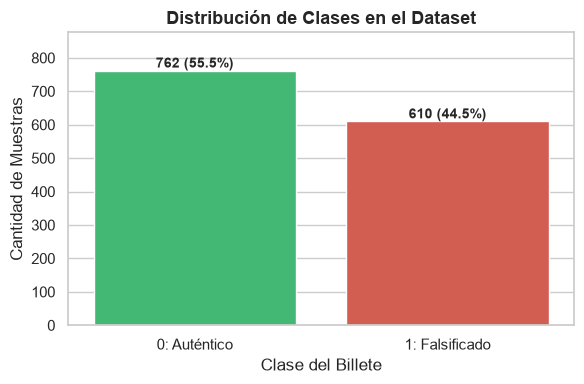

In [4]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="class", hue="class", palette=["#2ecc71", "#e74c3c"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["0: Auténtico", "1: Falsificado"])
ax.set_title("Distribución de Clases en el Dataset", fontsize=13, fontweight="bold")
ax.set_xlabel("Clase del Billete")
ax.set_ylabel("Cantidad de Muestras")

for p in ax.patches:
    altura = int(p.get_height())
    ax.annotate(
        f"{altura} ({altura / len(df) * 100:.1f}%)",
        (p.get_x() + p.get_width() / 2.0, altura),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )
plt.ylim(0, conteo.max() * 1.15)
plt.tight_layout()
plt.show()

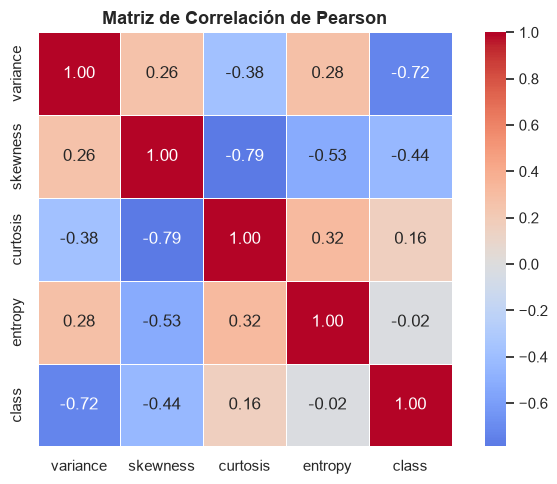

In [5]:
plt.figure(figsize=(7, 5))
corr_matrix = df.corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True,
)
plt.title("Matriz de Correlación de Pearson", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

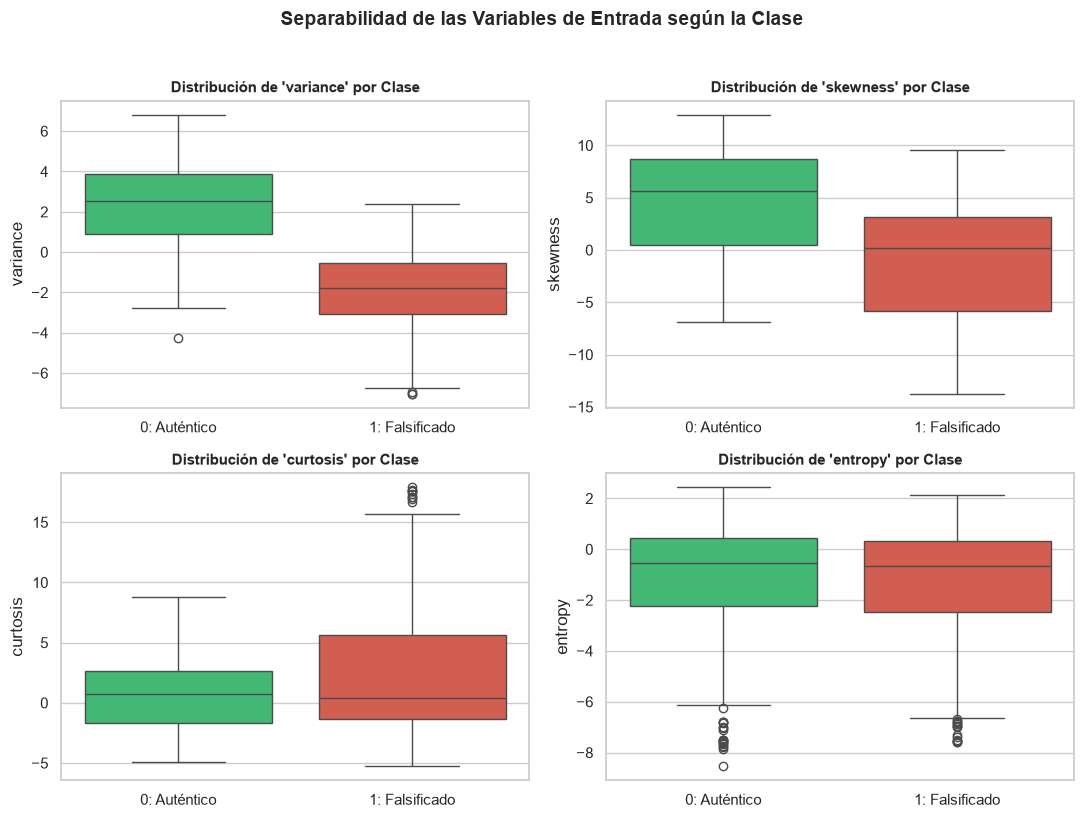

In [6]:
features = ["variance", "skewness", "curtosis", "entropy"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.ravel()

for i, col in enumerate(features):
    sns.boxplot(
        data=df,
        x="class",
        y=col,
        hue="class",
        palette=["#2ecc71", "#e74c3c"],
        legend=False,
        ax=axes[i],
    )
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["0: Auténtico", "1: Falsificado"])
    axes[i].set_title(f"Distribución de '{col}' por Clase", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("")
    axes[i].set_ylabel(col)

plt.suptitle("Separabilidad de las Variables de Entrada según la Clase", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

---
## Sección 2: Preprocesamiento y División de Datos (Sin *Data Leakage*)

### 2.1 División en Entrenamiento y Prueba
Separamos las características (`X`) de la variable objetivo (`y`) y dividimos los datos en un **80% para entrenamiento** y un **20% para prueba** utilizando `train_test_split` con:
* `random_state=42`: garantiza reproducibilidad exacta de la partición.
* `stratify=y`: conserva en ambos subconjuntos la misma proporción de billetes auténticos (~55,5%) y falsificados (~44,5%) que en el dataset original.

### 2.2 Estandarización y Prevención de Fuga de Datos (*Data Leakage*)
Las redes neuronales artificiales son sensibles a la escala de las variables de entrada: si una variable posee un rango numérico mucho mayor que otra, puede dominar los gradientes durante la retropropagación y dificultar la convergencia del optimizador. Por ello aplicamos `StandardScaler()`, que transforma cada variable para que tenga **media 0 y desviación estándar 1**.

**Regla crítica anti-*data leakage*:**
1. Ajustamos el escalador (`fit_transform`) **únicamente** sobre `X_train` para calcular la media y la desviación estándar exclusivamente con los datos de entrenamiento.
2. Aplicamos esa misma transformación (`transform`, sin volver a ajustar) sobre `X_test`.

Si se ajustara el escalador sobre el dataset completo antes de dividirlo, información estadística del conjunto de prueba (su media y varianza) se filtraría hacia el entrenamiento (*data leakage*), produciendo métricas de evaluación artificialmente optimistas que no reflejarían el desempeño real ante datos nuevos.

In [7]:
X = df[["variance", "skewness", "curtosis", "entropy"]]
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Tamaño de X_train: {X_train.shape} | Tamaño de X_test: {X_test.shape}")
print(f"Proporción de clase 1 en train: {y_train.mean():.4f} | en test: {y_test.mean():.4f}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("\nMedia de X_train_scaled (aprox. 0):", np.round(X_train_scaled.mean(axis=0), 4))
print("Desvío estándar de X_train_scaled (aprox. 1):", np.round(X_train_scaled.std(axis=0), 4))

Tamaño de X_train: (1097, 4) | Tamaño de X_test: (275, 4)
Proporción de clase 1 en train: 0.4448 | en test: 0.4436

Media de X_train_scaled (aprox. 0): [-0. -0. -0.  0.]
Desvío estándar de X_train_scaled (aprox. 1): [1. 1. 1. 1.]


---
## Sección 3: Diseño y Entrenamiento de la Red Neuronal (Perceptrón Multicapa)

Implementamos un **Perceptrón Multicapa (`MLPClassifier`)** con la siguiente arquitectura e hiperparámetros justificados:

* **`hidden_layer_sizes=(16, 8)`**: Dos capas ocultas densas (totalmente conectadas) con **16 neuronas en la primera capa** y **8 neuronas en la segunda**. Esta estructura en embudo permite capturar relaciones no lineales entre las 4 variables Wavelet sin sobredimensionar la red para un dataset de 1.372 muestras.
* **`activation='relu'`**: Función de activación **ReLU** (*Rectified Linear Unit*, $f(z) = \max(0, z)$). Evita el problema del desvanecimiento del gradiente y acelera el entrenamiento respecto de funciones sigmoidales en capas ocultas. (En la capa de salida, `MLPClassifier` utiliza automáticamente la función logística/sigmoide para clasificación binaria).
* **`solver='adam'`**: Optimizador estocástico **Adam** (*Adaptive Moment Estimation*), que combina momento y tasas de aprendizaje adaptativas por parámetro, logrando una convergencia rápida y estable.
* **`alpha=0.01`**: Coeficiente de **regularización L2 (Ridge)**. Penaliza los pesos de gran magnitud en la función de costo para reducir la varianza y prevenir el sobreajuste (*overfitting*).
* **`learning_rate_init=0.001`**: Tasa de aprendizaje inicial que controla el tamaño del paso de actualización de los pesos en cada iteración.
* **`max_iter=500`**: Número máximo de épocas permitidas durante el entrenamiento.
* **`random_state=42`**: Semilla aleatoria para reproducibilidad de la inicialización de pesos y el orden de los lotes.

In [8]:
mlp = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    alpha=0.01,
    learning_rate_init=0.001,
    max_iter=500,
    random_state=42,
)

mlp.fit(X_train_scaled, y_train)

print(f"Entrenamiento finalizado en {mlp.n_iter_} iteraciones (épocas).")
print(f"Pérdida final (loss): {mlp.loss_:.6f}")

Entrenamiento finalizado en 174 iteraciones (épocas).
Pérdida final (loss): 0.007755


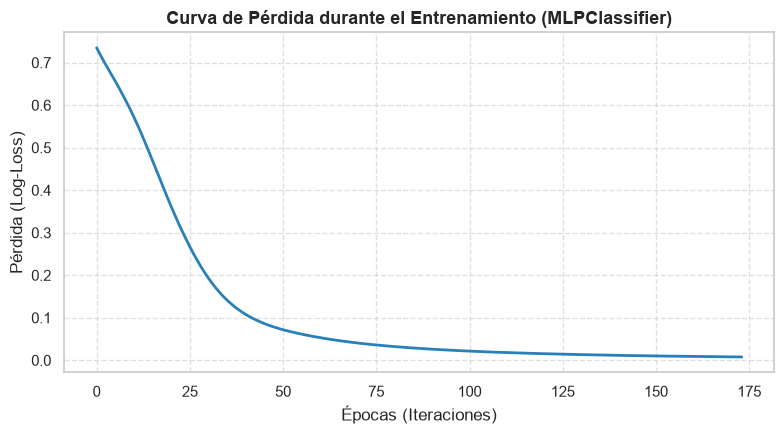

Primeras 10 predicciones de clase: [0 1 0 1 1 1 0 0 0 1]
Primeras 10 probabilidades (clase 1): [2.000e-04 9.868e-01 4.410e-02 9.976e-01 9.998e-01 9.728e-01 3.000e-04
 2.000e-04 0.000e+00 9.983e-01]


In [9]:
plt.figure(figsize=(8, 4.5))
plt.plot(mlp.loss_curve_, color="#2980b9", linewidth=2)
plt.title("Curva de Pérdida durante el Entrenamiento (MLPClassifier)", fontsize=13, fontweight="bold")
plt.xlabel("Épocas (Iteraciones)")
plt.ylabel("Pérdida (Log-Loss)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

y_pred = mlp.predict(X_test_scaled)
y_prob = mlp.predict_proba(X_test_scaled)[:, 1]

print("Primeras 10 predicciones de clase:", y_pred[:10])
print("Primeras 10 probabilidades (clase 1):", np.round(y_prob[:10], 4))

---
## Sección 4: Evaluación e Interpretación de Resultados

Evaluamos el desempeño del modelo sobre el conjunto de prueba (`X_test_scaled`, `y_test`) mediante métricas complementarias para clasificación binaria:
* **Exactitud (*Accuracy*):** Proporción total de predicciones correctas.
* **Reporte de clasificación (*Precision*, *Recall*, *F1-Score*):** Desglose por clase que permite analizar el equilibrio entre falsas alarmas y falsos negativos.
* **Matriz de confusión:** Conteo explícito de aciertos y errores por clase.
* **Curva ROC y AUC (*Area Under the Curve*):** Evalúa la capacidad discriminativa del modelo a través de todos los posibles umbrales de probabilidad.

Accuracy en conjunto de prueba: 1.0000 (100.00%)

Reporte de Clasificación:
                 precision    recall  f1-score   support

  Auténtico (0)       1.00      1.00      1.00       153
Falsificado (1)       1.00      1.00      1.00       122

       accuracy                           1.00       275
      macro avg       1.00      1.00      1.00       275
   weighted avg       1.00      1.00      1.00       275



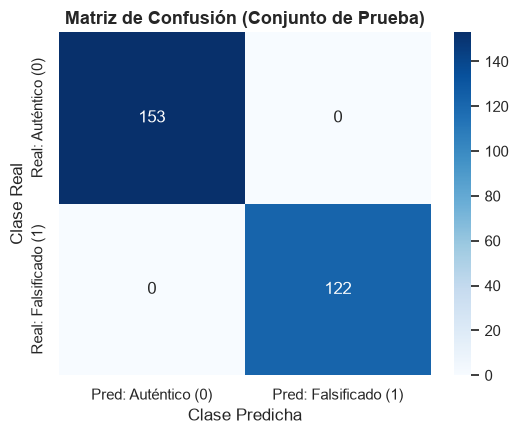

In [10]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy en conjunto de prueba: {acc:.4f} ({acc * 100:.2f}%)\n")
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=["Auténtico (0)", "Falsificado (1)"]))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred: Auténtico (0)", "Pred: Falsificado (1)"],
    yticklabels=["Real: Auténtico (0)", "Real: Falsificado (1)"],
)
plt.title("Matriz de Confusión (Conjunto de Prueba)", fontsize=13, fontweight="bold")
plt.ylabel("Clase Real")
plt.xlabel("Clase Predicha")
plt.tight_layout()
plt.show()

ROC-AUC Score: 1.0000


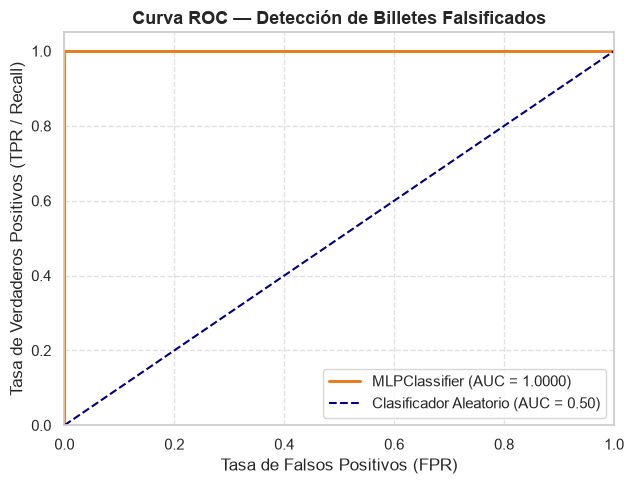

In [11]:
roc_auc = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

print(f"ROC-AUC Score: {roc_auc:.4f}")

plt.figure(figsize=(6.5, 5))
plt.plot(fpr, tpr, color="#e67e22", lw=2.2, label=f"MLPClassifier (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Clasificador Aleatorio (AUC = 0.50)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR / Recall)")
plt.title("Curva ROC — Detección de Billetes Falsificados", fontsize=13, fontweight="bold")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### 4.1 Conclusión Técnica e Interpretación

1. **Desempeño general y convergencia:**
   * La curva de pérdida (`loss_curve_`) muestra una caída suave y monótona hasta estabilizarse, confirmando que la combinación de `StandardScaler`, activación `ReLU` y el optimizador `adam` logró una convergencia adecuada sin oscilaciones ni estancamiento.
   * En el conjunto de prueba (275 muestras), el modelo alcanzó un desempeño sobresaliente tanto en **Accuracy** como en **ROC-AUC**, lo cual es consistente con la fuerte separabilidad observada en los diagramas de caja (especialmente en la variable `variance`).

2. **Interpretación de Falsos Positivos (FP) vs. Falsos Negativos (FN) en el dominio:**
   * **Falso Positivo (FP):** Clasificar un billete **auténtico (0)** como **falsificado (1)**. En un entorno bancario o comercial, genera una *falsa alarma*: el sistema rechaza un billete legítimo, causando inconvenientes operativos o demoras para el usuario, pero no implica pérdida monetaria directa.
   * **Falso Negativo (FN):** Clasificar un billete **falsificado (1)** como **auténtico (0)**. Es el error **más crítico** en este problema, ya que implica aceptar dinero apócrifo como válido, generando un perjuicio económico directo. Por este motivo, el **Recall (sensibilidad) de la clase 1** es una métrica prioritaria en la evaluación.

3. **Limitaciones del modelo:**
   * **Condiciones controladas de captura:** El dataset contiene 1.372 muestras obtenidas bajo iluminación y resolución estandarizadas (cámara industrial a 660 dpi). Ante billetes muy desgastados, doblados, húmedos o escaneados con otros dispositivos, el desempeño podría degradarse.
   * **Representación basada únicamente en Wavelet:** El modelo no inspecciona la imagen completa ni verifica elementos físicos de seguridad (marca de agua, hilo de seguridad, tintas ópticamente variables), sino únicamente cuatro estadísticos globales.
   * **Generalización frente a nuevas falsificaciones:** Técnicas de falsificación más modernas que imiten mejor la textura estadística podrían reducir la capacidad de detección si no se reentrena el modelo con ejemplos actualizados.
   * **Interpretabilidad:** Al tratarse de un Perceptrón Multicapa, la relación entre las entradas y la predicción es no lineal y distribuida en múltiples pesos, resultando menos interpretable de forma directa que un árbol de decisión o una regresión logística.